<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/4.%20Convolutions%20and%20CNN/Convolutional_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Convolutional Neural Network  - LeNet5 implementation.
- We will now implement [LeNet5](https://en.wikipedia.org/wiki/LeNet), a foundational Convolutional Neural Network from 1998. It was desined for machine digits or handwritten digits recognition
![LeNet](https://raw.githubusercontent.com/blurred-machine/Data-Science/master/Deep%20Learning%20SOTA/img/lenet-5.png)
- It uses the combination of both convolutional layers and linear layers to perform image classification by learning the featurs in an image.
- To downsample the input images, it uses maxpooling on the feature maps that we obtain after the convolution layers.
- The Image on the top shows the architecture of the LeNet5 and we'll see it in detail in the table below.
|Layer|Name|Number of channels|o/p-Feature Map|Size|Activation|
|-|-|-|-|-|-|
|1 - input|Image|1|32*32|-|-|
|2 -|convolution|6|28*28|5*5|relu|
|3 -|Max Pooling|6|14*14|2*2|relu|
|4 -|convolution|16|10*10|5*5|relu|
|5 -|Max Pooling|16|5*5|5*5|relu|
|6 -|FC|number of neurons = 400|120|-|relu|
|7 -|FC|number of neurons = 120|84|-|relu|
|8 -|FC|number of neurons = 84|10|-|softmax|

- We will use our favourite MNIST dataset, this time we will use pytorch dataset by using transform functionality of pytorch.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import random_split, dataloader

import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

## Let us get and prep our dataset

In [3]:
# let us calculate the mean and std for our dataset to normalise the dataset later
tem_dataset = datasets.MNIST(root ='./data', train = True, download = True, transform = transforms.ToTensor())
mean = tem_dataset.data.float().mean() / 255
std = tem_dataset.data.float().std() / 255
print('mean:',mean, 'std',std)
del tem_dataset

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 496kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.56MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.4MB/s]


mean: tensor(0.1307) std tensor(0.3081)


In [4]:
# we will make a transfrom for our dataset
transform = transforms.Compose([
    transforms.Resize(32),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
    ])

In [5]:
# train, validate and test datasets
train_dataset = datasets.MNIST('./data', train = True, download = True, transform = transform)
test_dataset = datasets.MNIST('./data', train = False, download = True, transform = transform)

# create a split for validationset
validation_split = 0.9

n_train_example = int(len(train_dataset) * validation_split)
n_validation_example = len(train_dataset) - n_train_example

# we can use pytorch's native method
# make the seed 42 to replicate same dataset everytime we run the script
generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset = random_split(train_dataset, [n_train_example, n_validation_example], generator= generator)

In [6]:
print(f'Number of training examples: {len(train_dataset)}')
print(f'Number of validation examples: {len(val_dataset)}')
print(f'Number of testing examples: {len(test_dataset)}')

Number of training examples: 54000
Number of validation examples: 6000
Number of testing examples: 10000


### dataloader to lood over during training

In [7]:
batch_size = 64

train_data_loader = dataloader.DataLoader(train_dataset, shuffle=True, batch_size = batch_size)
val_data_loader = dataloader.DataLoader(val_dataset, batch_size = batch_size)
test_data_loader = dataloader.DataLoader(test_dataset, batch_size = batch_size)

## Create the LeNet Architecture

In [8]:
class LeNet(nn.Module):
  def __init__(self, in_channels, num_classes):
    '''
    in_channels: the number of channels our input images have
    num_classes: the number of classes our dataset has
    '''
    super(LeNet, self).__init__()

    self.conv1 = nn.Conv2d(in_channels = in_channels, out_channels=6, kernel_size=(5,5))

    self.maxpool1 = nn.MaxPool2d(kernel_size=(2,2))

    self.conv2 = nn.Conv2d(in_channels = 6, out_channels= 16, kernel_size=(5,5))

    self.maxpool2 = nn.MaxPool2d(kernel_size=(2,2))

    #now linear layers
    self.flatten = nn.Flatten()

    self.linear1 = nn.Linear(in_features= 16*5*5, out_features=120)
    self.linear2 = nn.Linear(in_features= 120, out_features=84)
    self.linear3 = nn.Linear(in_features= 84, out_features=10)

  def forward(self, x):

    out1 = F.relu(self.conv1(x))

    out1 = self.maxpool1(out1)

    out2 = F.relu(self.conv2(out1))

    out2 = self.maxpool2(out2)

    #time to flatten out feature map
    out2 = self.flatten(out2)

    out3 = F.relu(self.linear1(out2))
    out4 = F.relu(self.linear2(out3))
    out5 = self.linear3(out4)

    return out5





### explore the output more


In [9]:
# one way to explore is to create a iterable object of test_data_loader
dataiter = iter(test_data_loader)
img , lab = next(dataiter)
print(img.shape)
print(lab.shape)

torch.Size([64, 1, 32, 32])
torch.Size([64])


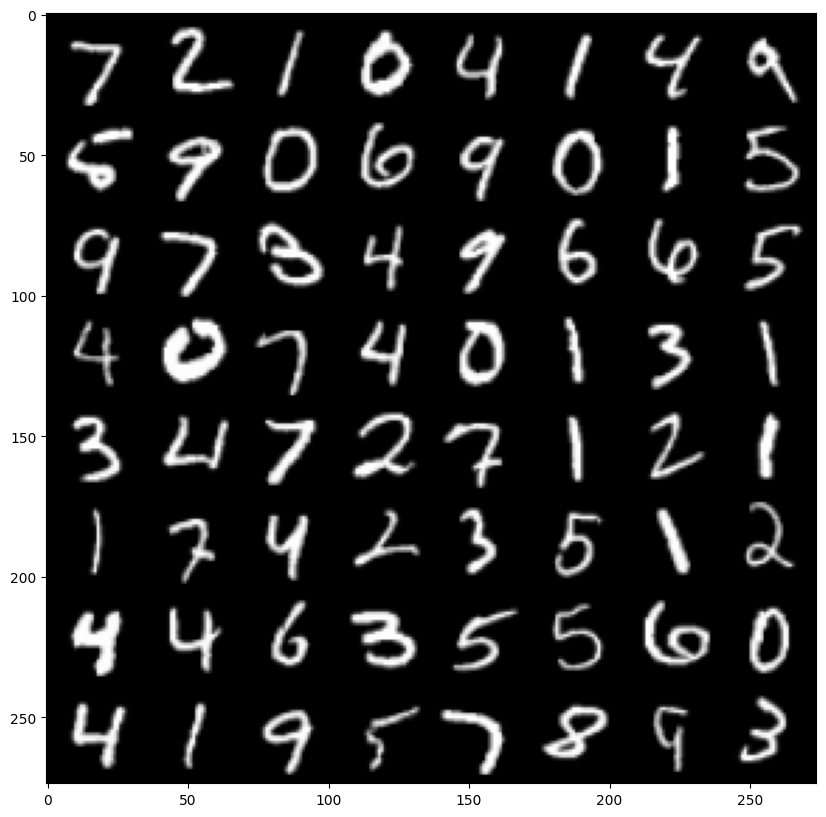

In [10]:
# Lets visualise an entire batch of images!

plt.figure(figsize = (20,10))
out = torchvision.utils.make_grid(img, 8, normalize=True)
plt.imshow(out.numpy().transpose((1, 2, 0)))

In [11]:
test_model = LeNet(img.shape[1],10)

print(test_model)

LeNet(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (maxpool1): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (maxpool2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=400, out_features=120, bias=True)
  (linear2): Linear(in_features=120, out_features=84, bias=True)
  (linear3): Linear(in_features=84, out_features=10, bias=True)
)


In [32]:
test_pred = test_model(img)
print(f'The initial predicted vales are : /n {test_pred.argmax(-1)[:8].numpy()}')
#print(torch.max(test_pred, dim = -1).indices, test_pred.shape)

The initial predicted vales are : /n [0 0 0 0 0 0 0 0]


## Train, Validate and Test

In [13]:
#make the gpu available
gpu_id = 0
device = torch.device(gpu_id if torch.cuda.is_available() else 'cpu')

### Make the model that we want to use and send it to gpu

In [28]:

dataiter = iter(train_data_loader)
test_img , test_lab = next(dataiter)
print(test_img.shape)
print(test_lab.shape)

torch.Size([64, 1, 32, 32])
torch.Size([64])


In [15]:
model = LeNet(img.shape[1],10)
model.to(device)

LeNet(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (maxpool1): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (maxpool2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=400, out_features=120, bias=True)
  (linear2): Linear(in_features=120, out_features=84, bias=True)
  (linear3): Linear(in_features=84, out_features=10, bias=True)
)

### optimizer and loss function


In [16]:
lr = 0.001
epochs = 5

optimizer = optim.Adam(model.parameters(), lr = lr)

In [17]:
loss_fn = nn.CrossEntropyLoss()

### Define the training

In [18]:
def train_epoch(model, optimizer, loss_fn, loss_logger, device):
  """
  Per epoch we iterate over all the mini batches from the datalogger
  """
  #setting the model in train mode- when we trained MLP with Linear layers, we do not need to use this but when working with
  # normalization (batcnorm layers) or regularization (dropout layers) layers we have to set the model to train or eval modes
  model.train()
  for i, (x,y) in enumerate(tqdm(train_data_loader, desc = 'Training',leave=False)):
    fx = model(x.to(device))

    loss = loss_fn(fx, y.to(device))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_logger.append(loss.item())

  return model, optimizer, loss_logger

In [19]:
def evaluate(model, device, loader):
  '''
  we use this evaluate function to both evaluate the model during training and testing
  '''
  epoch_acc = 0

  for i, (x,y) in enumerate(tqdm(loader, desc = 'Evaluating', leave = False)):

    out = model(x.to(device))

    epoch_acc += (out.argmax(dim=1) == y.to(device)).sum().item()


  return epoch_acc/len(loader.dataset)

- loop and train

In [20]:
training_loss_logger = []
validation_acc_logger = []
training_acc_logger = []

In [21]:
for eoch in tqdm(range(epochs), desc = "Epochs", leave = False):
  model, opt, training_loss_logger = train_epoch(model, optimizer, loss_fn, training_loss_logger, device)

  train_acc = evaluate(model, device, train_data_loader)
  val_acc = evaluate(model, device, val_data_loader)

  training_acc_logger.append(train_acc)
  validation_acc_logger.append(val_acc)

print('Training Finished')


Epochs:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/844 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/844 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/94 [00:00<?, ?it/s]

Training:   0%|          | 0/844 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/844 [00:00<?, ?it/s]

... (7 outputs left out)

Training:   0%|          | 0/844 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/844 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/94 [00:00<?, ?it/s]

Training Finished


In [34]:
print(f'The training accuracy is : {training_acc_logger[-1]*100:.2f}')
print(f'The validation accuracy is : {validation_acc_logger[-1]*100:.2f}')

The training accuracy is : 99.17
The validation accuracy is : 98.65


Text(0.5, 1.0, 'Training loss')

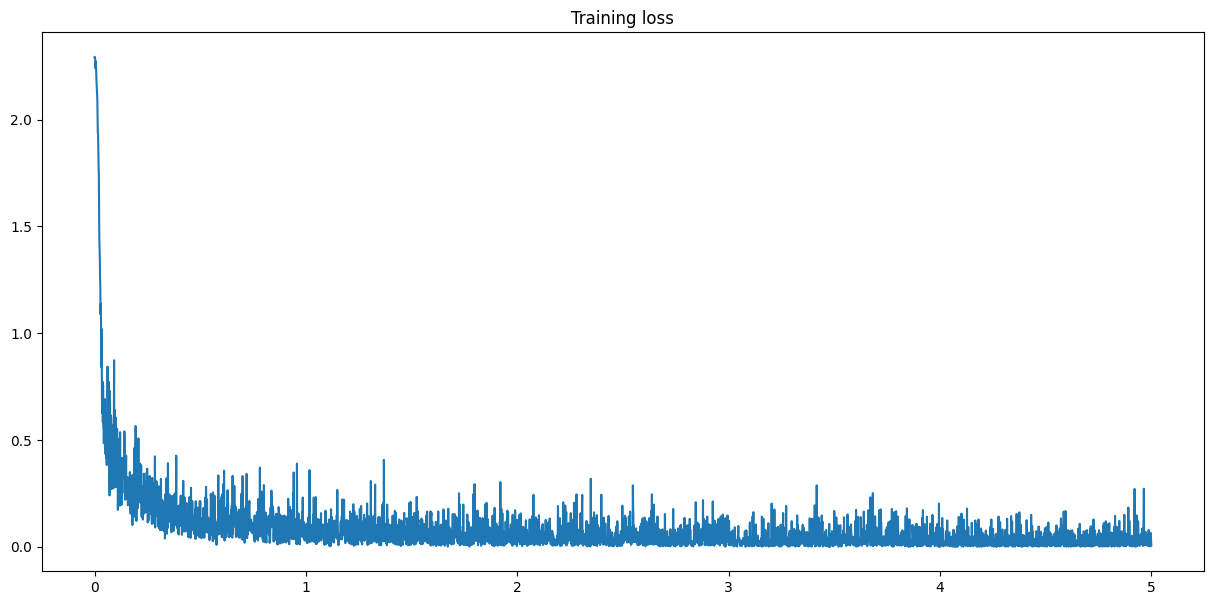

In [37]:
# plot the training graphs
plt.figure(figsize = (15,7))
x_axis = np.linspace(0, epochs, len(training_loss_logger))
plt.plot(x_axis, training_loss_logger, label = "Training loss")
plt.title('Training loss')

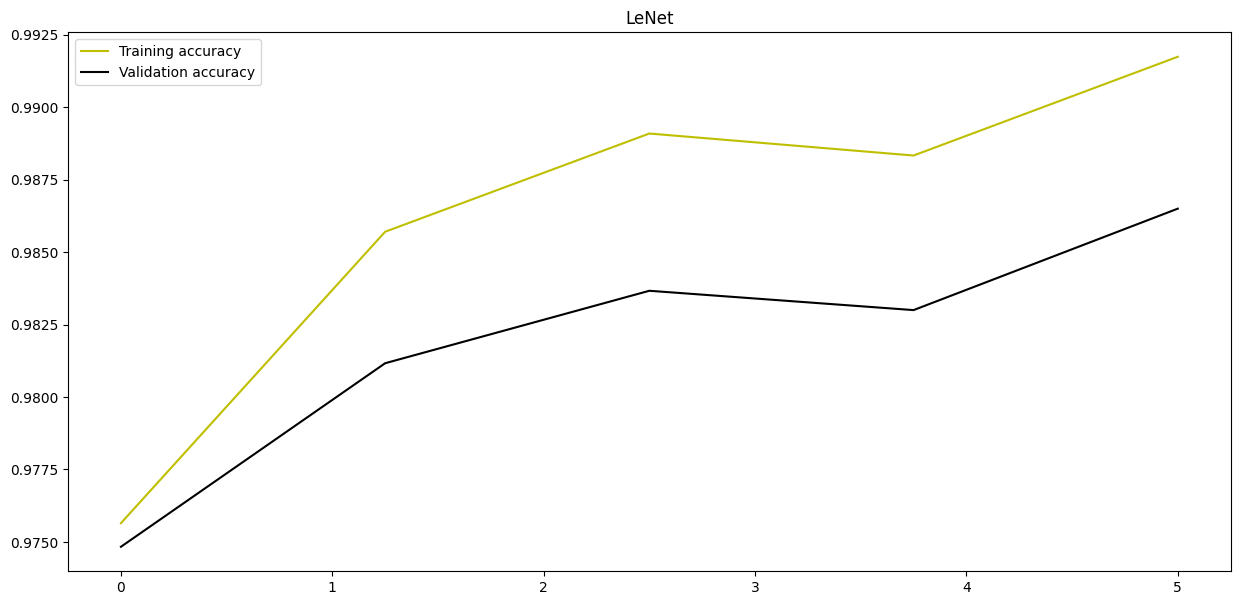

In [26]:
# Plot accuracy
plt.figure(figsize = (15,7))
train_x = np.linspace(0, epochs, len(training_acc_logger))
plt.plot(train_x, training_acc_logger, c = "y")
valid_x = np.linspace(0, epochs, len(validation_acc_logger))
plt.plot(valid_x, validation_acc_logger, c = "k")

plt.title("LeNet")
plt.legend(["Training accuracy", "Validation accuracy"])

### Evaluate on Test set

In [27]:
test_acc = evaluate(model, device, test_data_loader)
print(f'The testing accuracy is {test_acc*100:.2f}')

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

The testing accuracy is 98.83


The predicted values are : /n [np.int64(2), np.int64(5), np.int64(8), np.int64(6), np.int64(7), np.int64(0), np.int64(1), np.int64(0)]
 The True values are : /n [2 5 8 6 7 0 1 0]


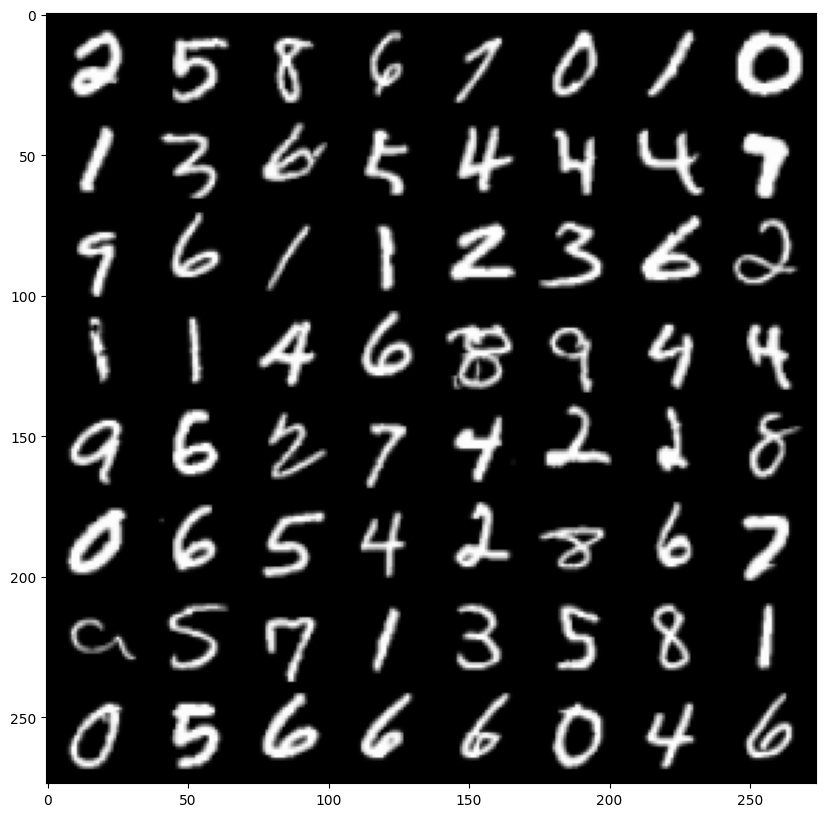

In [35]:
# we can also try to visualise the predictions on test data

with torch.no_grad():
  pred = model(test_img[:8].to(device))
  predictions = pred.argmax(dim = -1)

plt.figure(figsize = (20,10))
#make a pytorch grid
out = torchvision.utils.make_grid(test_img,8,normalize = True)
plt.imshow(out.numpy().transpose((1,2,0)))

print(f"The predicted values are : /n {list(predictions.cpu().numpy())}")
print(f" The True values are : /n {test_lab[:8].numpy()}")


- Even with a small training epochs of 5 we can see that the model converged very fast and predictions got very accurate.
- we can see the initial predictions of the untrained model are all 0's and the the trained model predicts all the first 8 test dataset images correctly